In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np

# Load the feature-engineered dataset
df = pd.read_csv("../dataset/ChargingRecords_Feature_Engineered.csv")

# Convert datetime columns
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])
df["EndDatetime"] = pd.to_datetime(df["EndDatetime"])

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (72826, 19)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,Hour,DayOfWeek,Month,YearMonth,IsWeekend,TimeOfDay
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,20,3,9,2022-09,0,Evening
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,20,2,9,2022-09,0,Evening
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,18,2,9,2022-09,0,Evening
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,18,3,9,2022-09,0,Evening
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,19,6,9,2022-09,1,Evening


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Column names:
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand', 'Hour', 'DayOfWeek', 'Month', 'YearMonth', 'IsWeekend', 'TimeOfDay']

Missing values:
0

Duplicate rows:
0


In [4]:
# Select input features
feature_columns = [
    "Location",
    "ChargerType",
    "ChargerCompany",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "TimeOfDay"
]

# Input variables
X = df[feature_columns]

# Target variable
y = df["Demand"]

print("Features selected:", X.shape)
print("Target selected:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Features selected: (72826, 8)
Target selected: (72826,)

Input features:
  Location  ChargerType  ChargerCompany  Hour  DayOfWeek  Month  IsWeekend  \
0    hotel            0               1    20          3      9          0   
1    hotel            0               1    20          2      9          0   
2    hotel            0               1    18          2      9          0   
3    hotel            0               1    18          3      9          0   
4    hotel            0               1    19          6      9          1   

  TimeOfDay  
0   Evening  
1   Evening  
2   Evening  
3   Evening  
4   Evening  

Target values:
0    20.36
1    10.19
2     6.78
3    37.65
4    33.81
Name: Demand, dtype: float64


In [5]:
# Sort records by charging start time
model_df = df.sort_values("StartDatetime").copy()

# Select features and target after sorting
X = model_df[feature_columns]
y = model_df["Demand"]

# 80% training and 20% testing
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (58260, 8)
Testing data: (14566, 8)


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [7]:
# Categorical features
categorical_features = ["Location", "TimeOfDay"]

# Numerical features
numerical_features = [
    "ChargerType",
    "ChargerCompany",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

print("Preprocessing setup completed!")

Preprocessing setup completed!


In [8]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [9]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn installed successfully!")

Scikit-learn version: 1.9.0
Scikit-learn installed successfully!


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [11]:
categorical_features = ["Location", "TimeOfDay"]

numerical_features = [
    "ChargerType",
    "ChargerCompany",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

print("Preprocessing setup completed!")

Preprocessing setup completed!


In [12]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [13]:
y_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

LINEAR REGRESSION RESULTS
-------------------------
MAE: 10.1936
MSE: 177.0961
RMSE: 13.3077
R2 Score: 0.0854


In [14]:
from sklearn.tree import DecisionTreeRegressor

print("Decision Tree imported successfully!")

Decision Tree imported successfully!


In [15]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=10,
            random_state=42
        ))
    ]
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [16]:
dt_pred = decision_tree_model.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("DECISION TREE RESULTS")
print("---------------------")
print("MAE:", round(dt_mae, 4))
print("MSE:", round(dt_mse, 4))
print("RMSE:", round(dt_rmse, 4))
print("R2 Score:", round(dt_r2, 4))

DECISION TREE RESULTS
---------------------
MAE: 10.2252
MSE: 179.8568
RMSE: 13.4111
R2 Score: 0.0712


In [17]:
from sklearn.ensemble import RandomForestRegressor

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [18]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [19]:
rf_pred = random_forest_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("MAE:", round(rf_mae, 4))
print("MSE:", round(rf_mse, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))

RANDOM FOREST RESULTS
---------------------
MAE: 10.2461
MSE: 182.5663
RMSE: 13.5117
R2 Score: 0.0572


In [20]:
from sklearn.ensemble import GradientBoostingRegressor

print("Gradient Boosting imported successfully!")

Gradient Boosting imported successfully!


In [21]:
gradient_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

gradient_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [22]:
gb_pred = gradient_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_pred)

print("GRADIENT BOOSTING RESULTS")
print("-------------------------")
print("MAE:", round(gb_mae, 4))
print("MSE:", round(gb_mse, 4))
print("RMSE:", round(gb_rmse, 4))
print("R2 Score:", round(gb_r2, 4))

GRADIENT BOOSTING RESULTS
-------------------------
MAE: 10.0916
MSE: 173.6174
RMSE: 13.1764
R2 Score: 0.1034


In [23]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [24]:
import xgboost

print("XGBoost version:", xgboost.__version__)
print("XGBoost installed successfully!")

XGBoost version: 3.4.1
XGBoost installed successfully!


In [25]:
from xgboost import XGBRegressor

print("XGBoost Regressor imported successfully!")

XGBoost Regressor imported successfully!


In [26]:
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            objective="reg:squarederror",
            n_jobs=-1
        ))
    ]
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [27]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [28]:
print("Preprocessor available:", "preprocessor" in globals())
print("Training data available:", "X_train" in globals())
print("Target data available:", "y_train" in globals())

Preprocessor available: True
Training data available: True
Target data available: True


In [29]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/ChargingRecords_Feature_Engineered.csv")

df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])
df["EndDatetime"] = pd.to_datetime(df["EndDatetime"])

print("Dataset loaded:", df.shape)

Dataset loaded: (72826, 19)


In [30]:
feature_columns = [
    "Location",
    "ChargerType",
    "ChargerCompany",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "TimeOfDay"
]

model_df = df.sort_values("StartDatetime").copy()

X = model_df[feature_columns]
y = model_df["Demand"]

split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (58260, 8)
Testing data: (14566, 8)


In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_features = ["Location", "TimeOfDay"]

numerical_features = [
    "ChargerType",
    "ChargerCompany",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [32]:
print("Preprocessor:", "preprocessor" in globals())
print("Training data:", "X_train" in globals())
print("Testing data:", "X_test" in globals())
print("Target:", "y_train" in globals())

Preprocessor: True
Training data: True
Testing data: True
Target: True


In [33]:
from xgboost import XGBRegressor

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [34]:
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            objective="reg:squarederror",
            n_jobs=-1
        ))
    ]
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [35]:
xgb_pred = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_mse = mean_squared_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(xgb_mse)
xgb_r2 = r2_score(y_test, xgb_pred)

print("XGBOOST RESULTS")
print("----------------")
print("MAE:", round(xgb_mae, 4))
print("MSE:", round(xgb_mse, 4))
print("RMSE:", round(xgb_rmse, 4))
print("R2 Score:", round(xgb_r2, 4))

XGBOOST RESULTS
----------------
MAE: 10.005
MSE: 172.3878
RMSE: 13.1297
R2 Score: 0.1097


In [36]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [37]:
import lightgbm

print("LightGBM version:", lightgbm.__version__)
print("LightGBM installed successfully!")

LightGBM version: 4.7.0
LightGBM installed successfully!


In [38]:
from lightgbm import LGBMRegressor

print("LightGBM Regressor imported successfully!")

LightGBM Regressor imported successfully!


In [39]:
lightgbm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LGBMRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        ))
    ]
)

lightgbm_model.fit(X_train, y_train)

print("LightGBM model trained successfully!")

LightGBM model trained successfully!


In [40]:
lgb_pred = lightgbm_model.predict(X_test)

lgb_mae = mean_absolute_error(y_test, lgb_pred)
lgb_mse = mean_squared_error(y_test, lgb_pred)
lgb_rmse = np.sqrt(lgb_mse)
lgb_r2 = r2_score(y_test, lgb_pred)

print("LIGHTGBM RESULTS")
print("----------------")
print("MAE:", round(lgb_mae, 4))
print("MSE:", round(lgb_mse, 4))
print("RMSE:", round(lgb_rmse, 4))
print("R2 Score:", round(lgb_r2, 4))

LIGHTGBM RESULTS
----------------
MAE: 10.003
MSE: 171.4324
RMSE: 13.0932
R2 Score: 0.1147


In [41]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost",
        "LightGBM"
    ],
    "MAE": [
        mae, dt_mae, rf_mae, gb_mae, xgb_mae, lgb_mae
    ],
    "MSE": [
        mse, dt_mse, rf_mse, gb_mse, xgb_mse, lgb_mse
    ],
    "RMSE": [
        rmse, dt_rmse, rf_rmse, gb_rmse, xgb_rmse, lgb_rmse
    ],
    "R2 Score": [
        r2, dt_r2, rf_r2, gb_r2, xgb_r2, lgb_r2
    ]
})

regression_results = regression_results.sort_values(
    by="R2 Score", ascending=False
)

display(regression_results)

regression_results.to_csv(
    "../dataset/regression_model_results.csv",
    index=False
)

print("Regression results saved successfully!")

,Model,MAE,MSE,RMSE,R2 Score
5,LightGBM,10.002959,171.432439,13.093221,0.114680
4,XGBoost,10.005011,172.387759,13.129652,0.109746
3,Gradient Boosting,10.091583,173.617442,13.176397,0.103396
0,Linear Regression,10.193635,177.096105,13.307746,0.085431
1,Decision Tree,10.225216,179.856802,13.411070,0.071174
2,Random Forest,10.246124,182.566324,13.511711,0.057181


Regression results saved successfully!


In [42]:
linear_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, linear_pred)
mse = mean_squared_error(y_test, linear_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, linear_pred)

print("Linear Regression metrics restored!")

Linear Regression metrics restored!


In [43]:
required_variables = [
    "linear_model",
    "decision_tree_model",
    "random_forest_model",
    "gradient_model",
    "xgb_model",
    "lightgbm_model"
]

for name in required_variables:
    print(name, ":", name in globals())

linear_model : True
decision_tree_model : True
random_forest_model : True
gradient_model : True
xgb_model : True
lightgbm_model : True


In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Regression libraries imported successfully!")

Regression libraries imported successfully!


In [45]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ))
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

gradient_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

print("Four missing models created successfully!")

Four missing models created successfully!


In [46]:
models_to_train = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_model
}

for name, model in models_to_train.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Training: Linear Regression
Linear Regression trained successfully!
Training: Decision Tree
Decision Tree trained successfully!
Training: Random Forest
Random Forest trained successfully!
Training: Gradient Boosting
Gradient Boosting trained successfully!


In [47]:
models = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_model,
    "XGBoost": xgb_model,
    "LightGBM": lightgbm_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

regression_results = pd.DataFrame(results)

regression_results = regression_results.sort_values(
    by="R2 Score",
    ascending=False
)

display(regression_results)

,Model,MAE,MSE,RMSE,R2 Score
5,LightGBM,10.002959,171.432439,13.093221,0.114680
4,XGBoost,10.005011,172.387759,13.129652,0.109746
3,Gradient Boosting,10.091583,173.617442,13.176397,0.103396
0,Linear Regression,10.193635,177.096105,13.307746,0.085431
1,Decision Tree,10.225216,179.856802,13.411070,0.071174
2,Random Forest,10.246124,182.566324,13.511711,0.057181


In [48]:
regression_results.to_csv(
    "../dataset/regression_model_results.csv",
    index=False
)

print("Regression results saved successfully!")

Regression results saved successfully!


In [49]:
# Calculate the median demand using training data
demand_threshold = y_train.median()

# Create High and Normal demand classes
y_train_class = (y_train >= demand_threshold).astype(int)
y_test_class = (y_test >= demand_threshold).astype(int)

print("Demand threshold:", demand_threshold)

print("\nTraining class distribution:")
print(y_train_class.value_counts())

print("\nTesting class distribution:")
print(y_test_class.value_counts())

Demand threshold: 14.2

Training class distribution:
Demand
1    29143
0    29117
Name: count, dtype: int64

Testing class distribution:
Demand
0    7464
1    7102
Name: count, dtype: int64


In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Classification libraries imported successfully!")

Classification libraries imported successfully!


In [51]:
classification_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=10,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "KNN": Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            eval_metric="logloss",
            n_jobs=-1
        ))
    ]),

    "LightGBM": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LGBMClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=5,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        ))
    ])
}

print("All seven classification models created successfully!")

All seven classification models created successfully!


In [52]:
from sklearn.svm import LinearSVC

classification_models["SVM"] = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearSVC(
        max_iter=3000,
        random_state=42
    ))
])

print("SVM model updated successfully!")

SVM model updated successfully!


In [53]:
for name in ["SVM", "XGBoost", "LightGBM"]:
    print("Training:", name)

    classification_models[name].fit(X_train, y_train_class)

    print(name, "trained successfully!")
    print("-" * 40)

Training: SVM
SVM trained successfully!
----------------------------------------
Training: XGBoost
XGBoost trained successfully!
----------------------------------------
Training: LightGBM
LightGBM trained successfully!
----------------------------------------


In [54]:
for name, model in classification_models.items():

    try:
        # Check whether the model has been fitted
        check = model.predict(X_test.head(5))

        print(name, ": Successfully Trained")

    except Exception as e:
        print(name, ": Not Trained")
        print("Error:", e)

Logistic Regression : Not Trained
Error: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
Decision Tree : Not Trained
Error: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
Random Forest : Not Trained
Error: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
KNN : Not Trained
Error: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
SVM : Successfully Trained
XGBoost : Successfully Trained
LightGBM : Successfully Trained


In [55]:
models_to_train = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "KNN"
]

for name in models_to_train:
    print("Training:", name)

    classification_models[name].fit(
        X_train,
        y_train_class
    )

    print(name, "trained successfully!")
    print("-" * 40)

Training: Logistic Regression
Logistic Regression trained successfully!
----------------------------------------
Training: Decision Tree
Decision Tree trained successfully!
----------------------------------------
Training: Random Forest
Random Forest trained successfully!
----------------------------------------
Training: KNN
KNN trained successfully!
----------------------------------------


In [56]:
for name, model in classification_models.items():
    try:
        model.predict(X_test.head(5))
        print(name, ": Successfully Trained")
    except Exception as e:
        print(name, ": Not Trained -", e)

Logistic Regression : Successfully Trained
Decision Tree : Successfully Trained
Random Forest : Successfully Trained
KNN : Successfully Trained
SVM : Successfully Trained
XGBoost : Successfully Trained
LightGBM : Successfully Trained


In [57]:
classification_results = []

for name, model in classification_models.items():

    predictions = model.predict(X_test)

    # Get prediction scores for ROC-AUC
    if hasattr(model.named_steps["model"], "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
    else:
        probabilities = model.decision_function(X_test)

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_class, predictions),
        "Precision": precision_score(y_test_class, predictions),
        "Recall": recall_score(y_test_class, predictions),
        "F1 Score": f1_score(y_test_class, predictions),
        "ROC-AUC": roc_auc_score(y_test_class, probabilities)
    })

classification_results_df = pd.DataFrame(classification_results)

classification_results_df = classification_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(classification_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
6,LightGBM,0.6427,0.6137,0.7213,0.6632,0.6917
5,XGBoost,0.6384,0.6143,0.6943,0.6519,0.6849
1,Decision Tree,0.6150,0.5889,0.6967,0.6383,0.6623
2,Random Forest,0.6282,0.6120,0.6488,0.6299,0.6739
0,Logistic Regression,0.6326,0.6191,0.6408,0.6298,0.6738
4,SVM,0.6324,0.6188,0.6408,0.6296,0.6734
3,KNN,0.5956,0.5814,0.6093,0.5950,0.6255


In [58]:
classification_results_df.to_csv(
    "../dataset/classification_model_results.csv",
    index=False
)

print("Classification results saved successfully!")

Classification results saved successfully!


In [62]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [63]:
import matplotlib
import seaborn

print("Matplotlib version:", matplotlib.__version__)
print("Seaborn version:", seaborn.__version__)
print("Both libraries installed successfully!")

Matplotlib version: 3.11.0
Seaborn version: 0.13.2
Both libraries installed successfully!


In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("All visualization libraries imported successfully!")

All visualization libraries imported successfully!


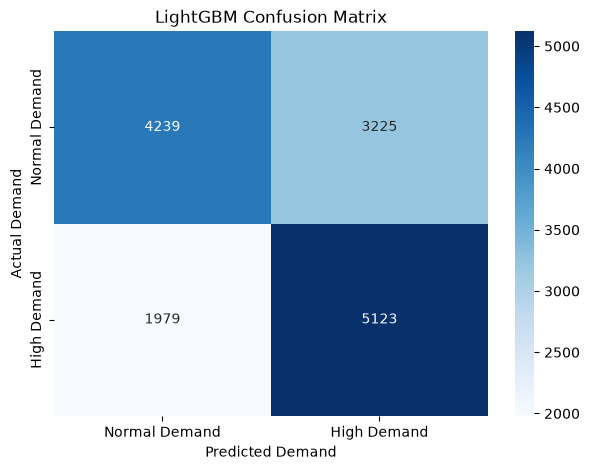

In [65]:
best_model = classification_models["LightGBM"]

y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test_class, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal Demand", "High Demand"],
    yticklabels=["Normal Demand", "High Demand"]
)

plt.xlabel("Predicted Demand")
plt.ylabel("Actual Demand")
plt.title("LightGBM Confusion Matrix")

plt.show()

In [66]:
# Extract trained LightGBM model
lgb_model = classification_models["LightGBM"].named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    classification_models["LightGBM"]
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance
importance = lgb_model.feature_importances_

# Create DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance_df)

,Feature,Importance
20,numerical__Hour,617
22,numerical__Month,570
21,numerical__DayOfWeek,281
19,numerical__ChargerCompany,279
18,numerical__ChargerType,187
7,categorical__Location_market,134
1,categorical__Location_apartment,102
11,categorical__Location_resort,97
6,categorical__Location_hotel,96
8,categorical__Location_public area,59


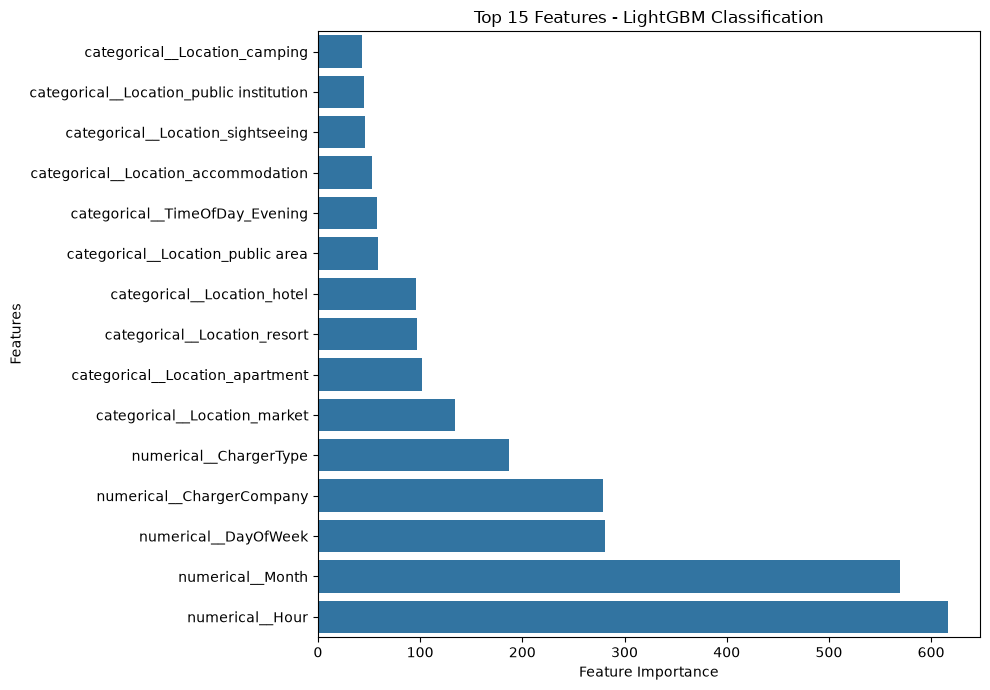

In [67]:
top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - LightGBM Classification")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [68]:
feature_importance_df.to_csv(
    "../dataset/feature_importance_results.csv",
    index=False
)

print("Feature importance results saved successfully!")

Feature importance results saved successfully!


In [69]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--


In [70]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP installed successfully!")

SHAP version: 0.54.1
SHAP installed successfully!


In [71]:
# Select the trained LightGBM pipeline
best_pipeline = classification_models["LightGBM"]

# Extract preprocessor and trained model
preprocessor = best_pipeline.named_steps["preprocessor"]
lgb_model = best_pipeline.named_steps["model"]

# Transform test data
X_test_transformed = preprocessor.transform(X_test)

# Select 500 records
X_shap = X_test_transformed[:500]

print("SHAP data prepared successfully!")
print("Sample shape:", X_shap.shape)

SHAP data prepared successfully!
Sample shape: (500, 24)


In [72]:
explainer = shap.TreeExplainer(lgb_model)

shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


C:\Users\ASUS\anaconda3\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


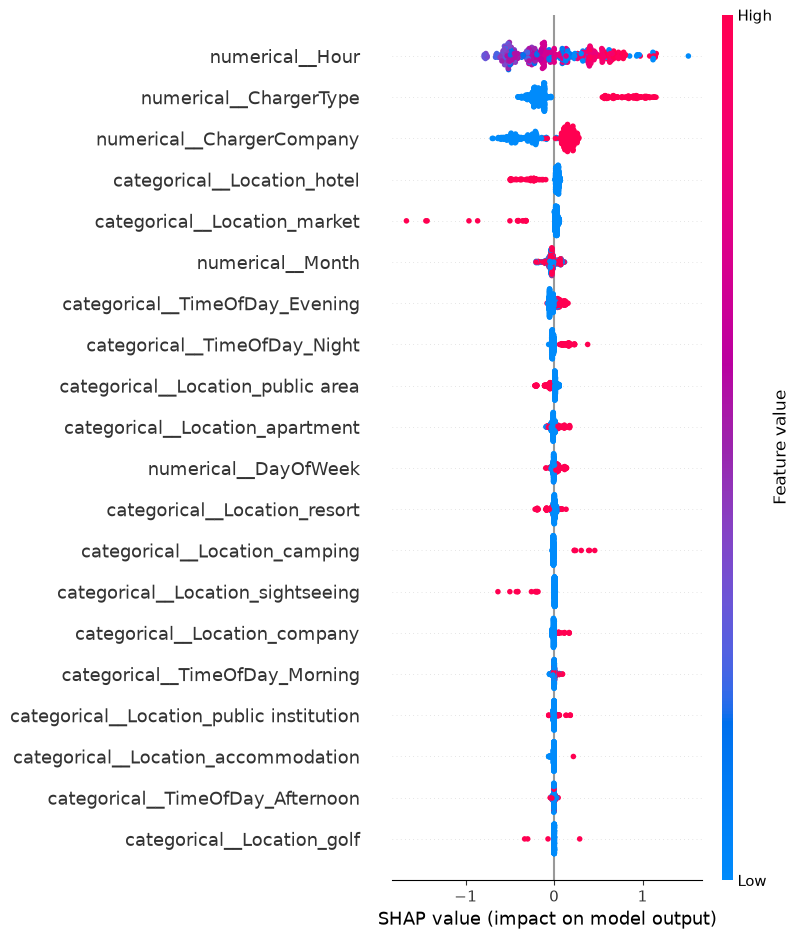

In [73]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    show=True
)

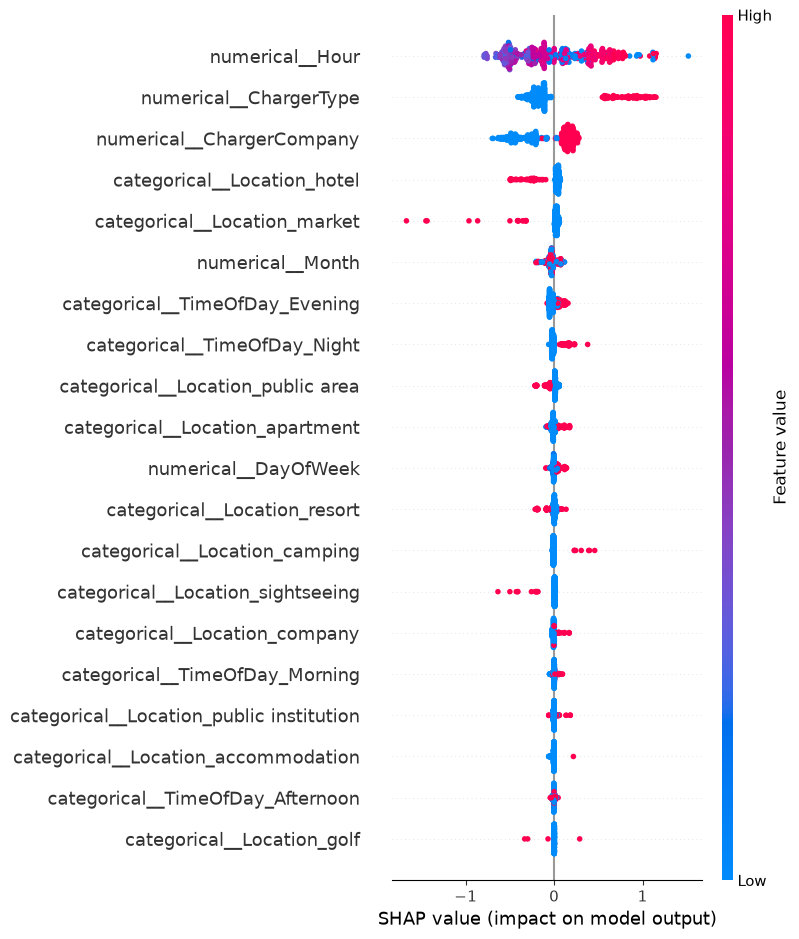

SHAP plot saved successfully!


In [74]:
plt.figure()
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    show=False
)

plt.savefig(
    "../dataset/SHAP_Summary_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP plot saved successfully!")

In [75]:
%pip install lime

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283918 sha256=e49287cb2aef925eebeee28375fa46fe0794980f43c72e77eba06650c3ec0ce6
  Stored in directory: c:\users\asus\appdata\local\pip\cache\wheels\eb\51\d9\c707b8fa7dee923cf3cb03edaf5c7f2bfeed5b91f5ca72f468
Successfully built lime
Note: you may need to restart the kernel to use updated packages.


In [76]:
import lime
from lime.lime_tabular import LimeTabularExplainer

print("LIME installed successfully!")

LIME installed successfully!


In [77]:
from lime.lime_tabular import LimeTabularExplainer

# Transform training data using the fitted preprocessor
X_train_transformed = preprocessor.transform(X_train)

# Convert sparse matrix to dense array if necessary
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

# Create LIME explainer
explainer_lime = LimeTabularExplainer(
    training_data=X_train_transformed,
    feature_names=feature_names,
    class_names=["Normal Demand", "High Demand"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer created successfully!")

LIME explainer created successfully!


In [78]:
# Select one test record
sample_index = 0

# Transform the selected record
sample_data = preprocessor.transform(
    X_test.iloc[[sample_index]]
)

if hasattr(sample_data, "toarray"):
    sample_data = sample_data.toarray()

sample_data = sample_data[0]

# Explain the prediction
lime_explanation = explainer_lime.explain_instance(
    sample_data,
    lgb_model.predict_proba,
    num_features=10
)

print("Actual class:", y_test_class.iloc[sample_index])
print("Predicted class:", lgb_model.predict_proba(
    preprocessor.transform(X_test.iloc[[sample_index]])
).argmax(axis=1)[0])

Actual class: 1
Predicted class: 1


In [79]:
lime_explanation.show_in_notebook(show_table=True)

ImportError: cannot import name 'display' from 'IPython.core.display' (C:\Users\ASUS\anaconda3\Lib\site-packages\IPython\core\display.py)

In [80]:
from IPython.display import display, HTML

print("IPython display imported successfully!")

IPython display imported successfully!


In [81]:
lime_html = lime_explanation.as_html()

display(HTML(lime_html))

In [82]:
lime_explanation.save_to_file(
    "../dataset/LIME_Explanation.html"
)

print("LIME explanation saved successfully!")

LIME explanation saved successfully!


In [83]:
display(df.describe(include="all"))

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,Hour,DayOfWeek,Month,YearMonth,IsWeekend,TimeOfDay
count,72826.000000,72826.000000,72826.000000,72826,72826.000000,72826,72826,72826,72826,72826,72826,72826.000000,72826.000000,72826.000000,72826.000000,72826.000000,72826,72826.000000,72826
unique,NaN,NaN,NaN,14,NaN,366,43240,365,46702,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13,NaN,4
top,NaN,NaN,NaN,public area,NaN,2022-08-10,18:28:39,2022-07-28,4:10:01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2022-08,NaN,Evening
freq,NaN,NaN,NaN,14076,NaN,310,8,310,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8083,NaN,23125
mean,337.978208,525.319172,0.627647,NaN,0.205009,NaN,NaN,NaN,NaN,2022-04-19 11:59:54.617581,2022-04-19 14:35:26.723422,151.222105,17.440366,14.610922,2.927430,6.244116,NaN,0.259866,NaN
min,0.000000,1.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,2021-09-30 17:14:00,2021-10-01 00:07:00,0.000000,0.010000,0.000000,0.000000,1.000000,NaN,0.000000,NaN
25%,0.000000,107.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,NaN,2022-01-25 21:36:30,2022-01-26 02:06:00,40.000000,7.530000,11.000000,1.000000,4.000000,NaN,0.000000,NaN
50%,61.000000,300.000000,1.000000,NaN,0.000000,NaN,NaN,NaN,NaN,2022-04-27 14:29:00,2022-04-27 15:43:30,112.000000,14.100000,16.000000,3.000000,6.000000,NaN,0.000000,NaN
75%,407.000000,738.000000,1.000000,NaN,0.000000,NaN,NaN,NaN,NaN,2022-07-17 10:18:45,2022-07-17 11:53:30,202.000000,23.200000,19.000000,5.000000,9.000000,NaN,1.000000,NaN
max,2501.000000,2671.000000,1.000000,NaN,1.000000,NaN,NaN,NaN,NaN,2022-09-30 23:11:00,2022-09-30 23:52:00,1573.000000,97.000000,23.000000,6.000000,12.000000,NaN,1.000000,NaN


In [1]:
import joblib
import os

# Create models folder
os.makedirs("../models", exist_ok=True)

# Save LightGBM classification model
joblib.dump(
    lightgbm_classifier,
    "../models/lightgbm_classifier.pkl"
)

print("LightGBM classifier saved successfully!")

NameError: name 'lightgbm_classifier' is not defined

In [2]:
import pandas as pd
import numpy as np
import os
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

# Load dataset
df = pd.read_csv("../dataset/ChargingRecords_Feature_Engineered.csv")
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])

# Define features
feature_columns = [
    "Location", "ChargerType", "ChargerCompany",
    "Hour", "DayOfWeek", "Month", "IsWeekend", "TimeOfDay"
]

# Create classification target
threshold = df["Demand"].median()

df["Demand_Category"] = np.where(
    df["Demand"] >= threshold, "High", "Normal"
)

# Chronological train-test split
model_df = df.sort_values("StartDatetime").copy()

X = model_df[feature_columns]
y = model_df["Demand_Category"]

split_index = int(len(model_df) * 0.80)

X_train_class = X.iloc[:split_index]
y_train_class = y.iloc[:split_index]

# Create preprocessor
preprocessor = ColumnTransformer([
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     ["Location", "TimeOfDay"]),

    ("numerical",
     StandardScaler(),
     ["ChargerType", "ChargerCompany",
      "Hour", "DayOfWeek", "Month", "IsWeekend"])
])

# Create and train LightGBM
lightgbm_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

lightgbm_classifier.fit(X_train_class, y_train_class)

print("LightGBM classifier recreated successfully!")

LightGBM classifier recreated successfully!


In [3]:
os.makedirs("../models", exist_ok=True)

joblib.dump(
    lightgbm_classifier,
    "../models/lightgbm_classifier.pkl"
)

print("LightGBM classifier saved successfully!")

LightGBM classifier saved successfully!


In [4]:
import os

model_path = "../models/lightgbm_classifier.pkl"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model size:", round(os.path.getsize(model_path) / 1024, 2), "KB")

Model exists: True
Model size: 342.87 KB


In [5]:
print(lightgbm_model)

NameError: name 'lightgbm_model' is not defined

In [6]:
import pandas as pd
import numpy as np
import os
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from lightgbm import LGBMRegressor

# Load feature-engineered dataset
df = pd.read_csv("../dataset/ChargingRecords_Feature_Engineered.csv")

df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])

# Define input features
feature_columns = [
    "Location",
    "ChargerType",
    "ChargerCompany",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "TimeOfDay"
]

# Sort data chronologically
model_df = df.sort_values("StartDatetime").copy()

X = model_df[feature_columns]
y = model_df["Demand"]

# Chronological 80:20 split
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["Location", "TimeOfDay"]
        ),
        (
            "numerical",
            StandardScaler(),
            [
                "ChargerType",
                "ChargerCompany",
                "Hour",
                "DayOfWeek",
                "Month",
                "IsWeekend"
            ]
        )
    ]
)

# Create LightGBM regression pipeline
lightgbm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

# Train model
lightgbm_model.fit(X_train, y_train)

print("LightGBM regression model trained successfully!")

LightGBM regression model trained successfully!


In [7]:
os.makedirs("../models", exist_ok=True)

joblib.dump(
    lightgbm_model,
    "../models/lightgbm_regressor.pkl"
)

print("LightGBM regression model saved successfully!")

LightGBM regression model saved successfully!


In [8]:
import os

model_path = "../models/lightgbm_regressor.pkl"

print("Regression model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print(
        "Model size:",
        round(os.path.getsize(model_path) / 1024, 2),
        "KB"
    )

Regression model exists: True
Model size: 260.72 KB
